# Projecting the LFP onto motif directions: two poles, or sub-motifs?

Mouse 720762, deep prelimbic LFP (PL5), stimulation-free data, for the awake, isoflurane and full windows. The axes
are the motifs found by the relaxed version of getMotifs (saved in results.json). Each second's z-scored band
envelopes are projected onto one motif axis at a time. The opponent is the same axis pointing the other way, so
a motif and its opponent are the two ends of a single line.

Two clusters along the line would mean discrete poles. More clusters would mean sub-motifs: the same pattern at
different intensities. One hump would mean a continuum.

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from diptest import diptest

sys.path.insert(0, "..")
from src import session_data as sd
from src.state_motifs import BANDS, COLORS, FS, WINDOWS, band_labels, envelope_pieces, restrict, zscore
%matplotlib inline

REPO = Path.cwd().resolve().parents[2]
NWB = REPO / "data" / "raw" / "720762-20240221-v001.nwb"
RESULTS = REPO / "data" / "out" / "2026-11-01_mouse720762" / "results.json"
PROBE, REGION, SIGNAL, VERSION = "probeF", "PL5", "lfp_PL5", "relaxed"
N_NULL = 200
labels = band_labels()

## Load the data and the motif directions

In [2]:
io, nwb = sd.open_nwb(NWB)
info = sd.read_info(nwb, NWB.name)
segments, windows = sd.stim_free_segments(info), sd.analysis_windows(info)
channel = sd.lfp_channel(nwb, PROBE, REGION)
t, x, fs = sd.decimate(*sd.read_raw(nwb, ("lfp", PROBE, channel)), FS)
io.close()
hop = int(round(fs))
pieces = envelope_pieces(t, x, fs, segments)

R = json.loads(RESULTS.read_text().replace("NaN", "null"))
data = {}
for win in WINDOWS:
    z = zscore(restrict(pieces, windows[win], fs))
    run = next(r for r in R["motif_runs"] if r["signal"] == SIGNAL and r["window"] == win and r["version"] == VERSION)
    motif = np.array(run["motifs"])[:, 0]
    data[win] = {"t": np.concatenate([p.t[::hop] for p in z]), "X": np.concatenate([p.env[::hop] for p in z]),
                 "stretch": np.concatenate([np.full(p.t[::hop].size, i) for i, p in enumerate(z)]),
                 "motif": motif, "axis": motif / np.linalg.norm(motif)}
    d = data[win]
    d["score"] = d["X"] @ d["axis"]
    d["trivial"] = np.abs(np.sign(d["X"]).sum(axis=1)) == d["X"].shape[1]

pd.DataFrame({w: dict(zip(labels, d["motif"].round(2))) for w, d in data.items()})

,awake,isoflurane,full
1-4,-0.60,0.26,-0.72
3-6,0.59,-0.37,0.25
5-9,-0.10,-0.57,0.51
8-12,0.66,-0.48,-0.68
10-15,0.66,-0.49,-0.80
13-20,0.62,-0.10,-0.68
18-30,0.27,0.19,-0.12
25-40,0.06,0.46,0.50
35-55,-0.01,0.66,0.71
50-80,0.36,0.78,0.96


## Is the distribution along each axis one hump, two poles, or more?

The null shifts each band in time within its stretch, like the motif null: each band keeps its own dynamics, but any real pattern across bands is destroyed. Hartigan's dip statistic measures how far a distribution is from having one peak. Comparing it with the null accounts for neighbouring seconds being correlated.

In [3]:
rng = np.random.default_rng(0)

def null_scores(d):
    X = d["X"].copy()
    for s in np.unique(d["stretch"]):
        k = np.flatnonzero(d["stretch"] == s)
        for b in range(X.shape[1]):
            X[k, b] = np.roll(X[k, b], rng.integers(k.size))
    return X @ d["axis"]

rows = []
for win, d in data.items():
    d["nulls"] = np.array([null_scores(d) for _ in range(N_NULL)])
    dip = diptest(d["score"])[0]
    null_dips = np.array([diptest(s)[0] for s in d["nulls"]])
    d["dip_p"] = (1 + (null_dips >= dip).sum()) / (N_NULL + 1)
    rows.append({"window": win, "seconds": d["score"].size, "dip": dip, "null dip (median)": np.median(null_dips),
                 "p vs null": d["dip_p"], "SD real": d["score"].std(), "SD null": d["nulls"].std(),
                 "share all-same-sign": d["trivial"].mean()})
pd.DataFrame(rows).round(4)

,window,seconds,dip,null dip (median),p vs null,SD real,SD null,share all-same-sign
0,awake,1537,0.0117,0.0071,0.0846,1.8845,1.3109,0.0046
1,isoflurane,1973,0.0225,0.0053,0.0050,0.9750,1.0943,0.4972
2,full,3688,0.0786,0.0309,0.0050,1.5712,1.2642,0.1565


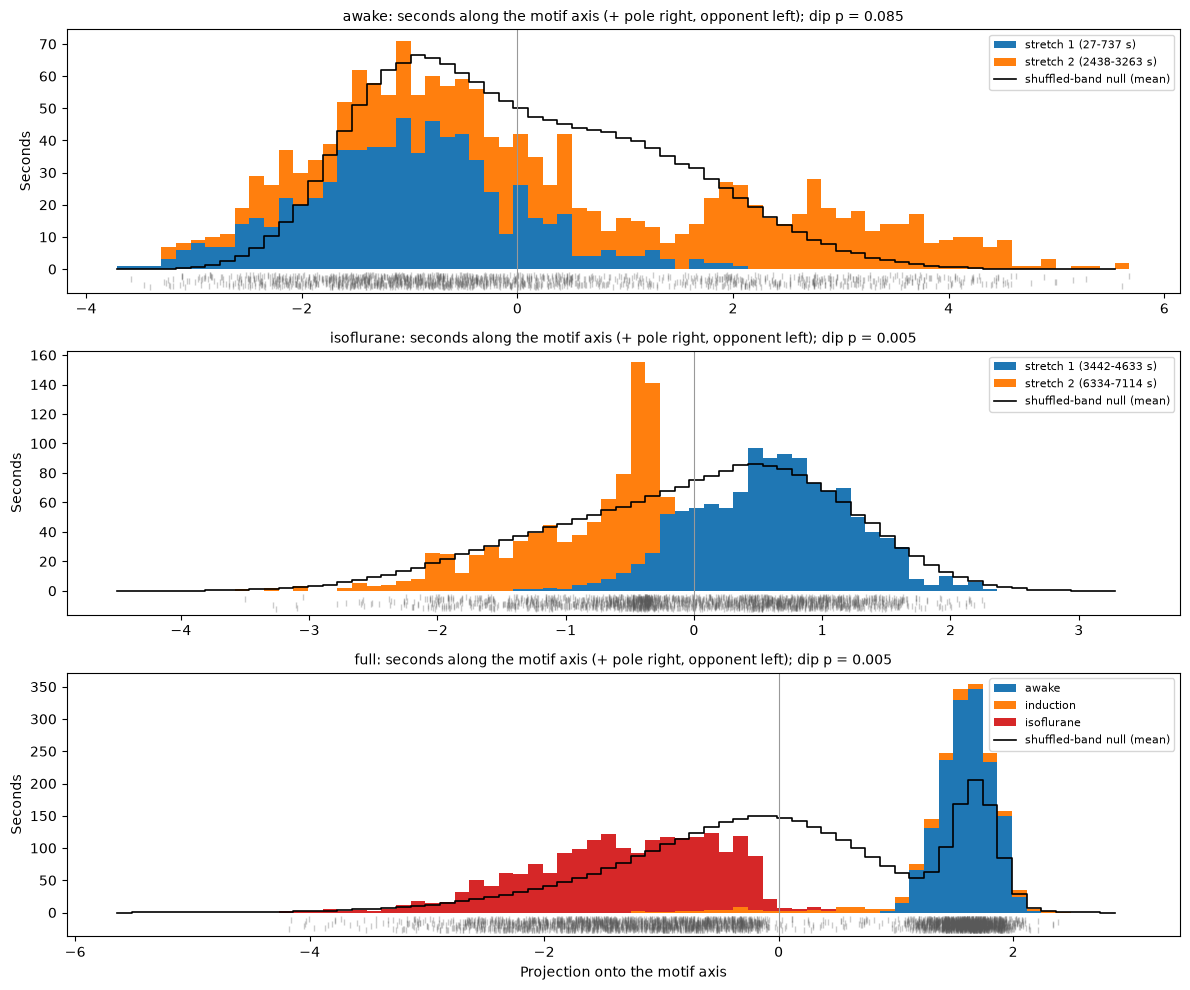

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
for ax, (win, d) in zip(axes, data.items()):
    s = d["score"]
    edges = np.linspace(min(s.min(), d["nulls"].min()), max(s.max(), d["nulls"].max()), 70)
    if win == "full":
        groups = sd.state_of_time(d["t"], info)
        parts = [(s[groups == g], g, COLORS[g]) for g in ("awake", "induction", "isoflurane")]
    else:
        parts = [(s[d["stretch"] == i], f"stretch {i + 1} ({d['t'][d['stretch'] == i][0]:.0f}-{d['t'][d['stretch'] == i][-1]:.0f} s)", c)
                 for i, c in zip(np.unique(d["stretch"]), ("C0", "C1", "C2"))]
    ax.hist([p[0] for p in parts], bins=edges, stacked=True, color=[p[2] for p in parts], label=[p[1] for p in parts])
    null_counts = np.array([np.histogram(n, edges)[0] for n in d["nulls"]]).mean(axis=0)
    ax.step(edges[:-1], null_counts, where="post", color="k", lw=1.2, label="shuffled-band null (mean)")
    top = ax.get_ylim()[1]
    ax.plot(s, np.full(s.size, -0.05 * top) + rng.uniform(-0.025, 0.025, s.size) * top, "|", ms=4, color="0.35", alpha=0.3)
    ax.axvline(0, color="0.6", lw=0.8)
    ax.set_ylim(-0.1 * top, top)
    ax.set_title(f"{win}: seconds along the motif axis (+ pole right, opponent left); dip p = {d['dip_p']:.3f}", fontsize=10)
    ax.set_ylabel("Seconds")
    ax.legend(fontsize=8)
axes[-1].set_xlabel("Projection onto the motif axis")
fig.tight_layout()

## Sub-motifs: do low-intensity seconds have the same pattern?

Seconds are split into 10 equal groups along the axis. If the axis is one pattern at different intensities, each group's mean band profile should be the motif (or its opponent) scaled up or down. A real sub-motif would show a different band shape in some groups, meaning a low correlation with the motif even though the group sits away from zero.

,awake,awake score,isoflurane,isoflurane score,full,full score
group 0,-0.96,-2.52,-0.99,-1.83,-0.93,-2.57
group 1,-0.98,-1.80,-0.99,-1.03,-0.98,-1.79
group 2,-0.98,-1.37,-0.97,-0.58,-0.99,-1.34
group 3,-0.97,-1.02,-0.43,-0.39,-0.94,-0.91
group 4,-0.94,-0.67,-0.44,-0.18,-0.77,-0.51
group 5,-0.35,-0.29,0.50,0.21,0.79,0.54
group 6,0.50,0.25,0.95,0.52,0.99,1.43
group 7,0.93,1.28,0.98,0.76,0.99,1.58
group 8,0.99,2.43,0.97,1.04,0.99,1.70
group 9,0.99,3.75,0.97,1.50,1.00,1.89


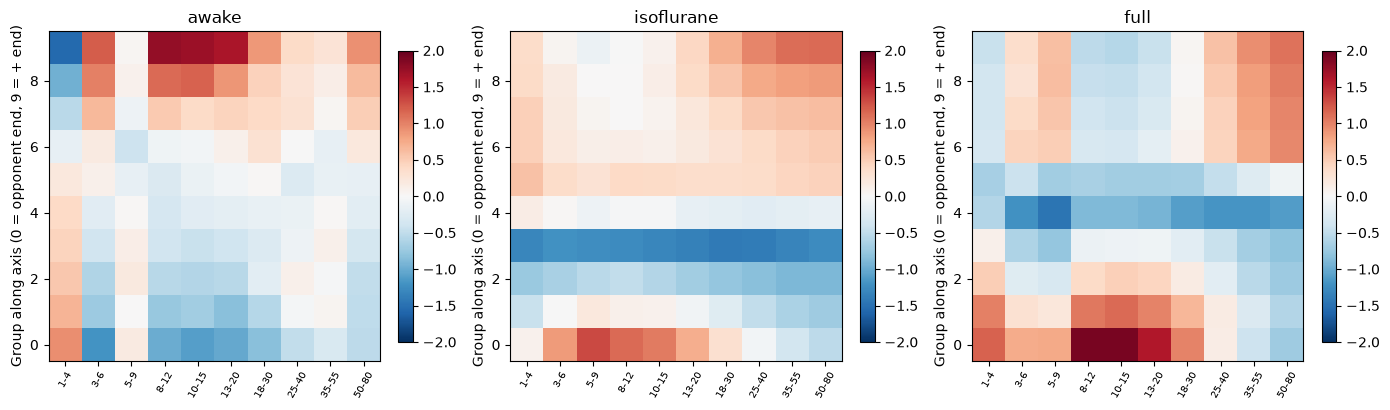

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
table = {}
for ax, (win, d) in zip(axes, data.items()):
    order = np.argsort(d["score"])
    groups = np.array_split(order, 10)
    profiles = np.array([d["X"][g].mean(axis=0) for g in groups])
    im = ax.imshow(profiles, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto", origin="lower")
    ax.set_xticks(range(len(labels)), labels, rotation=60, fontsize=7)
    ax.set_ylabel("Group along axis (0 = opponent end, 9 = + end)")
    ax.set_title(win)
    fig.colorbar(im, ax=ax, fraction=0.04)
    table[win] = {f"group {i}": np.corrcoef(p, d["motif"])[0, 1] for i, p in enumerate(profiles)}
    table[win + " score"] = {f"group {i}": d["score"][g].mean() for i, g in enumerate(groups)}
fig.tight_layout()
pd.DataFrame(table).round(2)

## What are the features of these distributions?

Two checks on what the plots suggest: does the awake right-hand tail line up with the visual-stimulus block, and is the sharp isoflurane spike a state where every band is low?

In [6]:
d = data["awake"]
_, v0, v1 = info.visual_blocks[0]
visual = (d["t"] >= v0) & (d["t"] <= v1)
high = d["score"] > 1.5
print(f"awake: {high.sum()} seconds score above 1.5; {visual[high].mean():.0%} of them are in the visual block, "
      f"which is {visual.mean():.0%} of awake seconds")
print(f"mean score: visual block {d['score'][visual].mean():.2f}, rest {d['score'][~visual].mean():.2f}")

d = data["isoflurane"]
late = d["stretch"] == 1
spike = late & (d["score"] > -0.6) & (d["score"] < -0.2)
print(f"isoflurane spike: {spike.sum()} seconds ({spike.mean():.0%}); {(d['X'][spike] < 0).all(axis=1).mean():.0%} have every band "
      f"below average (other seconds: {(d['X'][~spike] < 0).all(axis=1).mean():.0%})")
within = (d["score"][late].var() * late.sum() + d["score"][~late].var() * (~late).sum()) / (d["score"].var() * late.size)
print(f"share of variance along the isoflurane axis that is between the two stretches: {1 - within:.0%}")

awake: 366 seconds score above 1.5; 82% of them are in the visual block, which is 36% of awake seconds
mean score: visual block 1.31, rest -0.73
isoflurane spike: 324 seconds (16%); 95% have every band below average (other seconds: 12%)
share of variance along the isoflurane axis that is between the two stretches: 62%


## Conclusions

- **No evidence for sub-motifs in the sense of separate clusters at different intensities.** Within a state, seconds spread continuously along each motif axis, and their band profile keeps the motif's shape, scaled by distance from zero. Intensity looks like a continuous quantity, not discrete levels.
- **Poles are not two discrete clusters within a state.** Awake is not significantly multi-peaked (dip p = 0.085). "Which pole dominates" cuts a continuum in two.
- **The peaks that do exist have other explanations:**
  - Full recording: two clear peaks, which are the two states.
  - Isoflurane: two humps, which are the two stretches of the window (62% of the variance along this axis is between them).
  - Isoflurane spike: a distinct state in which every band is low (burst suppression). It is a different pattern, not a weaker motif.
- **The awake + pole is concentrated in the visual-stimulus block** (82% of high-scoring seconds, in 36% of the time). Visual stimulation and time in the session can't be separated here.

Limits: one channel, one mouse, 10 bands.